# Lösung: Datensatz vorbereiten und prüfen

Wir verwenden den öffentlichen Datensatz **„Small object detection for euro coins“** (Version 5) von Roboflow Universe, Lizenz **Public Domain**:
https://universe.roboflow.com/hlcv2023finalproject/small-object-detection-for-euro-coins

1. Datensatz herunterladen
2. Reduzieren: Duplikate entfernen und Klassen umnummerieren
3. Labels prüfen
4. Eigene Fotos ergänzen und nach Szenen aufteilen

## Umgebung

Für Colab `use_colab = True` setzen. Der Ordner `Datensätze` liegt dann in Google Drive.

In [1]:
use_colab = False

if use_colab:
    from google.colab import drive
    drive.mount("/content/drive")
    base_path = "/content/drive/MyDrive"
else:
    base_path = ".."

import os
from pathlib import Path
import cv2
import matplotlib.pyplot as plt


def show_image(image_bgr, title="", size=(8, 8)):
    plt.figure(figsize=size)
    plt.imshow(cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB))
    plt.title(title)
    plt.axis("off")
    plt.show()

## 1. Datensatz herunterladen

1. Bei Roboflow kostenlos anmelden und die Seite des Datensatzes öffnen
2. Version 5 wählen, **Download Dataset**, Format **YOLOv8**, **Download zip to computer**
3. Die ZIP-Datei nach `Datensätze/muenzen` entpacken

Danach liegen dort `data.yaml` sowie die Ordner `train`, `valid` und `test`.

In [2]:
src_dir = Path(base_path) / "Datensätze" / "muenzen"
print(open(src_dir / "data.yaml", encoding="utf-8").read())
for split in ["train", "valid", "test"]:
    print(split, len(list((src_dir / split / "images").glob("*.jpg"))), "Bilder")

train: ../train/images
val: ../valid/images
test: ../test/images

nc: 8
names: ['EUR-1-cent', 'EUR-1-euro', 'EUR-10-cent', 'EUR-2-cent', 'EUR-2-euro', 'EUR-20-cent', 'EUR-5-cent', 'EUR-50-cent']

roboflow:
  workspace: hlcv2023finalproject
  project: small-object-detection-for-euro-coins
  version: 5
  license: Public Domain
  url: https://universe.roboflow.com/hlcv2023finalproject/small-object-detection-for-euro-coins/dataset/5
train 1311 Bilder
valid 146 Bilder
test 122 Bilder


## 2. Datensatz reduzieren

Beim Blick auf die Dateinamen fällt auf: Viele Trainingsbilder gibt es **dreifach**, etwa `20210321_094710_jpg.rf.8041….jpg`, `…rf.8703….jpg` und `…rf.9640….jpg`. Roboflow hat bei früheren Versionen augmentierte Kopien als eigene Bilder gespeichert. Ultralytics augmentiert beim Training ohnehin selbst, die Kopien kosten also nur Rechenzeit.

Wir behalten **ein Bild pro Quellbild** und nummerieren die Klassen in die Reihenfolge der Vorlesung um (1 ct bis 2 €).

In [3]:
import re
import shutil
from pathlib import Path

ROBOFLOW_NAMES = ["EUR-1-cent", "EUR-1-euro", "EUR-10-cent", "EUR-2-cent",
                  "EUR-2-euro", "EUR-20-cent", "EUR-5-cent", "EUR-50-cent"]
CLASSES = ["1ct", "2ct", "5ct", "10ct", "20ct", "50ct", "1eur", "2eur"]
ID_MAP = {0: 0, 1: 6, 2: 3, 3: 1, 4: 7, 5: 4, 6: 2, 7: 5}   # Roboflow-ID -> ID in der Vorlesung
SPLITS = {"train": "train", "valid": "val", "test": "test"}


def write_data_yaml(target, comment):
    (target / "data.yaml").write_text(
        comment + "train: images/train\nval: images/val\ntest: images/test\n\nnames:\n"
        + "".join(f"  {i}: {k}\n" for i, k in enumerate(CLASSES)), encoding="utf-8")


def reduce_dataset(src_dir, target):
    src_dir, target = Path(src_dir), Path(target)
    counts = {}
    for src_split, split in SPLITS.items():
        (target / "images" / split).mkdir(parents=True, exist_ok=True)
        (target / "labels" / split).mkdir(parents=True, exist_ok=True)
        seen = set()
        for image in sorted((src_dir / src_split / "images").glob("*.jpg")):
            source_name = re.sub(r"\.rf\..*", "", image.name)
            if source_name in seen:          # Duplikat eines bereits übernommenen Quellbilds
                continue
            seen.add(source_name)
            label = src_dir / src_split / "labels" / f"{image.stem}.txt"
            lines = [l.split() for l in label.read_text().splitlines() if l.strip()] if label.exists() else []
            rows = [" ".join([str(ID_MAP[int(p[0])])] + p[1:]) for p in lines]
            shutil.copy(image, target / "images" / split / f"{source_name}.jpg")
            (target / "labels" / split / f"{source_name}.txt").write_text(
                "\n".join(rows) + ("\n" if rows else ""))
        counts[split] = len(seen)
    write_data_yaml(target,
        "# Reduzierte Fassung von \"Small object detection for euro coins\" (v5)\n"
        "# https://universe.roboflow.com/hlcv2023finalproject/small-object-detection-for-euro-coins\n"
        "# Lizenz: Public Domain. Ohne Duplikate.\n")
    return counts

In [4]:
target = Path(base_path) / "Datensätze" / "muenzen_klein"
if not (target / "data.yaml").exists():
    print(reduce_dataset(src_dir, target))
print(open(target / "data.yaml", encoding="utf-8").read())

# Reduzierte Fassung von "Small object detection for euro coins" (v5)
# https://universe.roboflow.com/hlcv2023finalproject/small-object-detection-for-euro-coins
# Lizenz: Public Domain. Ohne Duplikate.
train: images/train
val: images/val
test: images/test

names:
  0: 1ct
  1: 2ct
  2: 5ct
  3: 10ct
  4: 20ct
  5: 50ct
  6: 1eur
  7: 2eur



## 3. Labels prüfen

In [5]:
import pandas as pd


def read_labels(dataset, split):
    rows, num_background = [], 0
    for image in sorted((Path(dataset) / "images" / split).glob("*.jpg")):
        file = Path(dataset) / "labels" / split / f"{image.stem}.txt"
        content = [z for z in file.read_text().splitlines() if z.strip()] if file.exists() else []
        if not content:
            num_background += 1
        for z in content:
            k, x, y, w, h = z.split()
            rows.append({"image": image.name, "coin_class": int(k), "xc": float(x),
                         "yc": float(y), "w": float(w), "h": float(h)})
    return pd.DataFrame(rows), num_background


df, num_background = read_labels(target, "train")
print(f"{len(df)} Münzen, {df.image.nunique()} Bilder mit Münzen, {num_background} Hintergrundbilder")

assert df.coin_class.between(0, len(CLASSES) - 1).all(), "unbekannte Klassen-ID"
assert df[["xc", "yc", "w", "h"]].apply(lambda s: s.between(0, 1)).all().all(), "Werte außerhalb [0, 1]"
print("Alle Labels plausibel")

3666 Münzen, 473 Bilder mit Münzen, 39 Hintergrundbilder
Alle Labels plausibel


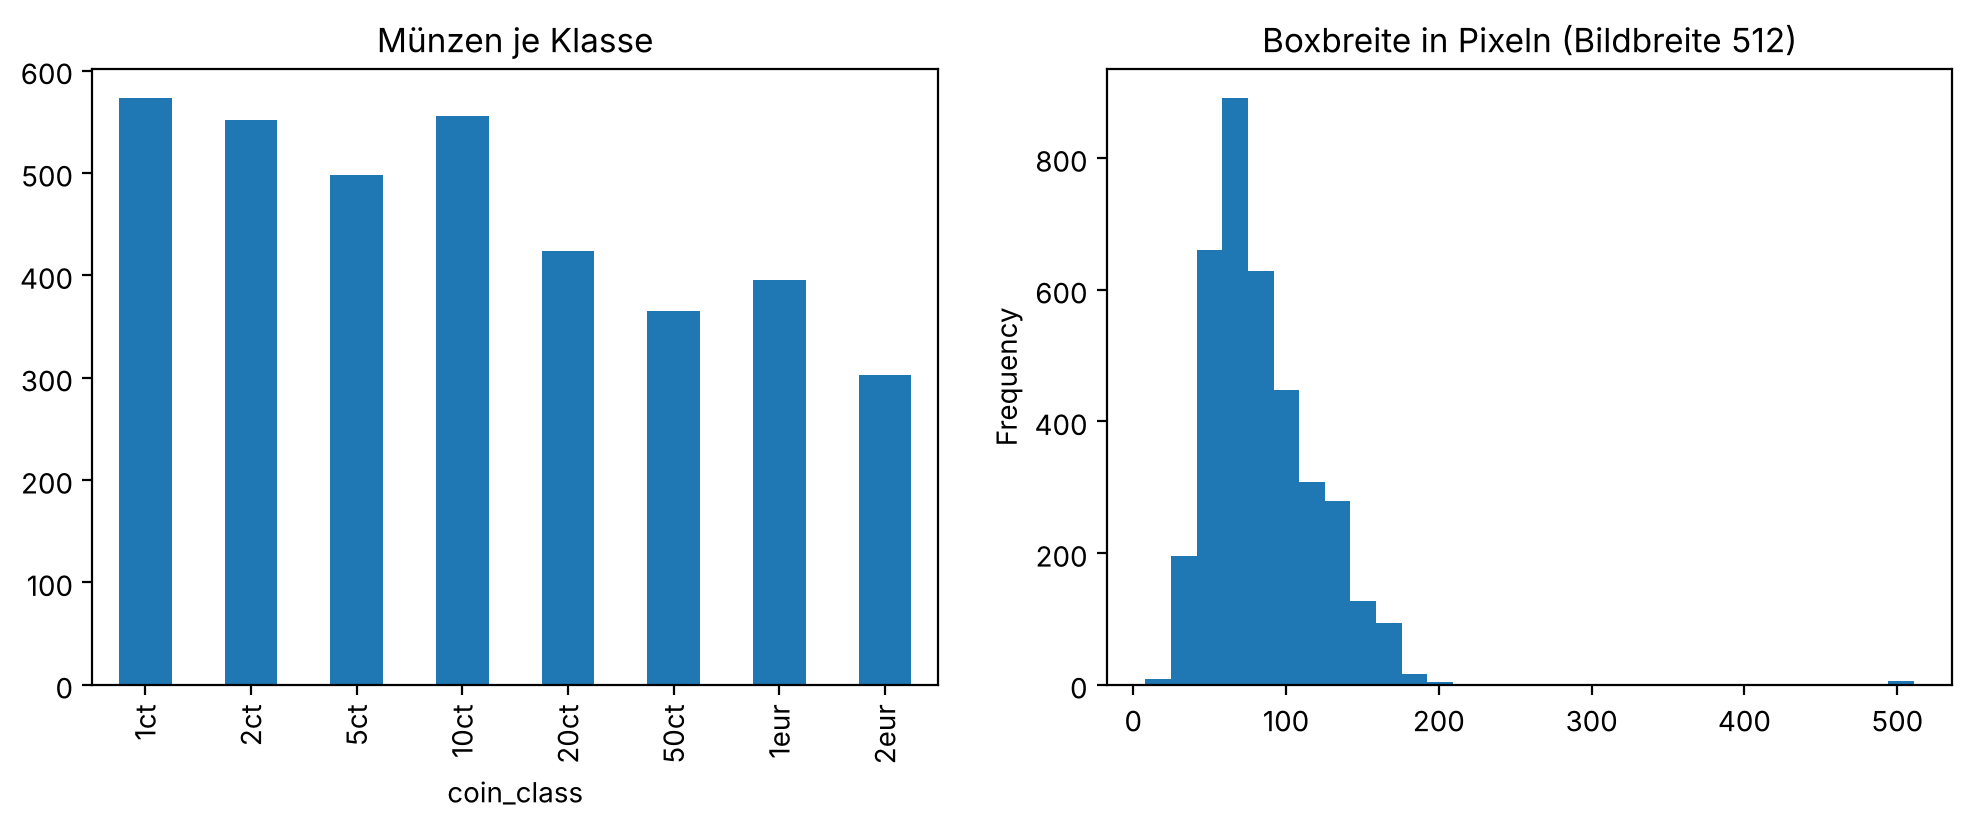

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df.coin_class.map(dict(enumerate(CLASSES))).value_counts().reindex(CLASSES).plot.bar(ax=ax[0])
ax[0].set_title("Münzen je Klasse")
(df.w * 512).plot.hist(bins=30, ax=ax[1])
ax[1].set_title("Boxbreite in Pixeln (Bildbreite 512)")
plt.show()

Sichtprüfung: Liegen die Boxen eng an, und stimmen die Klassen?

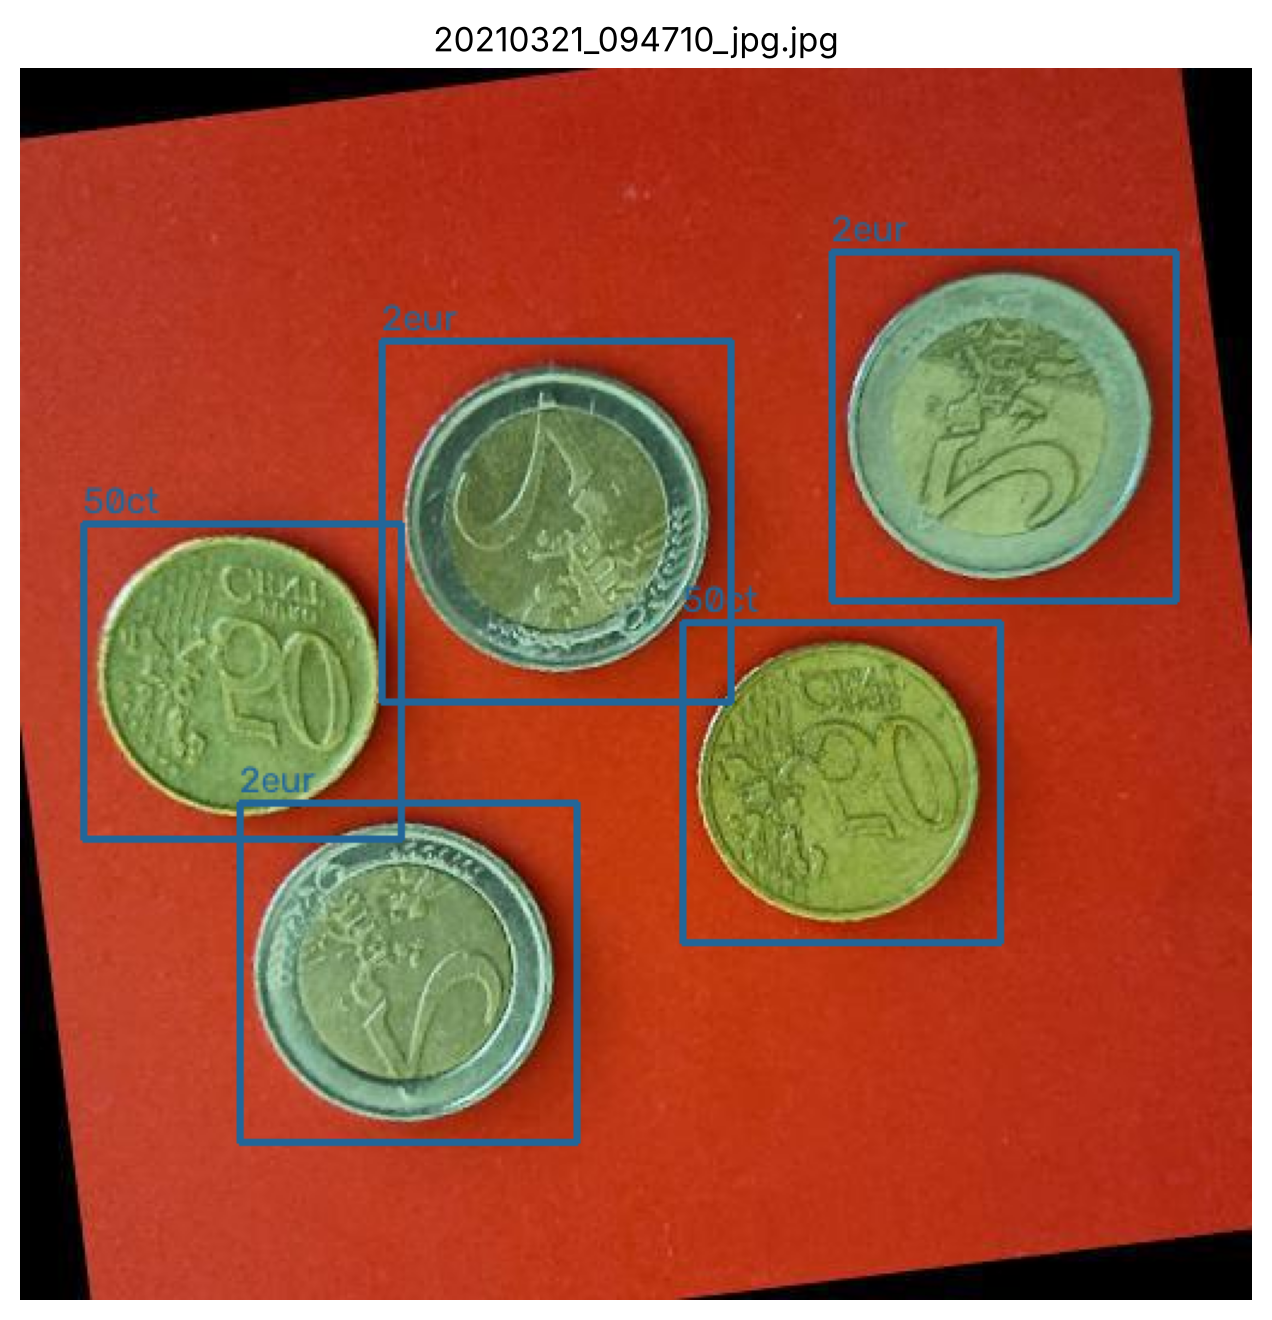

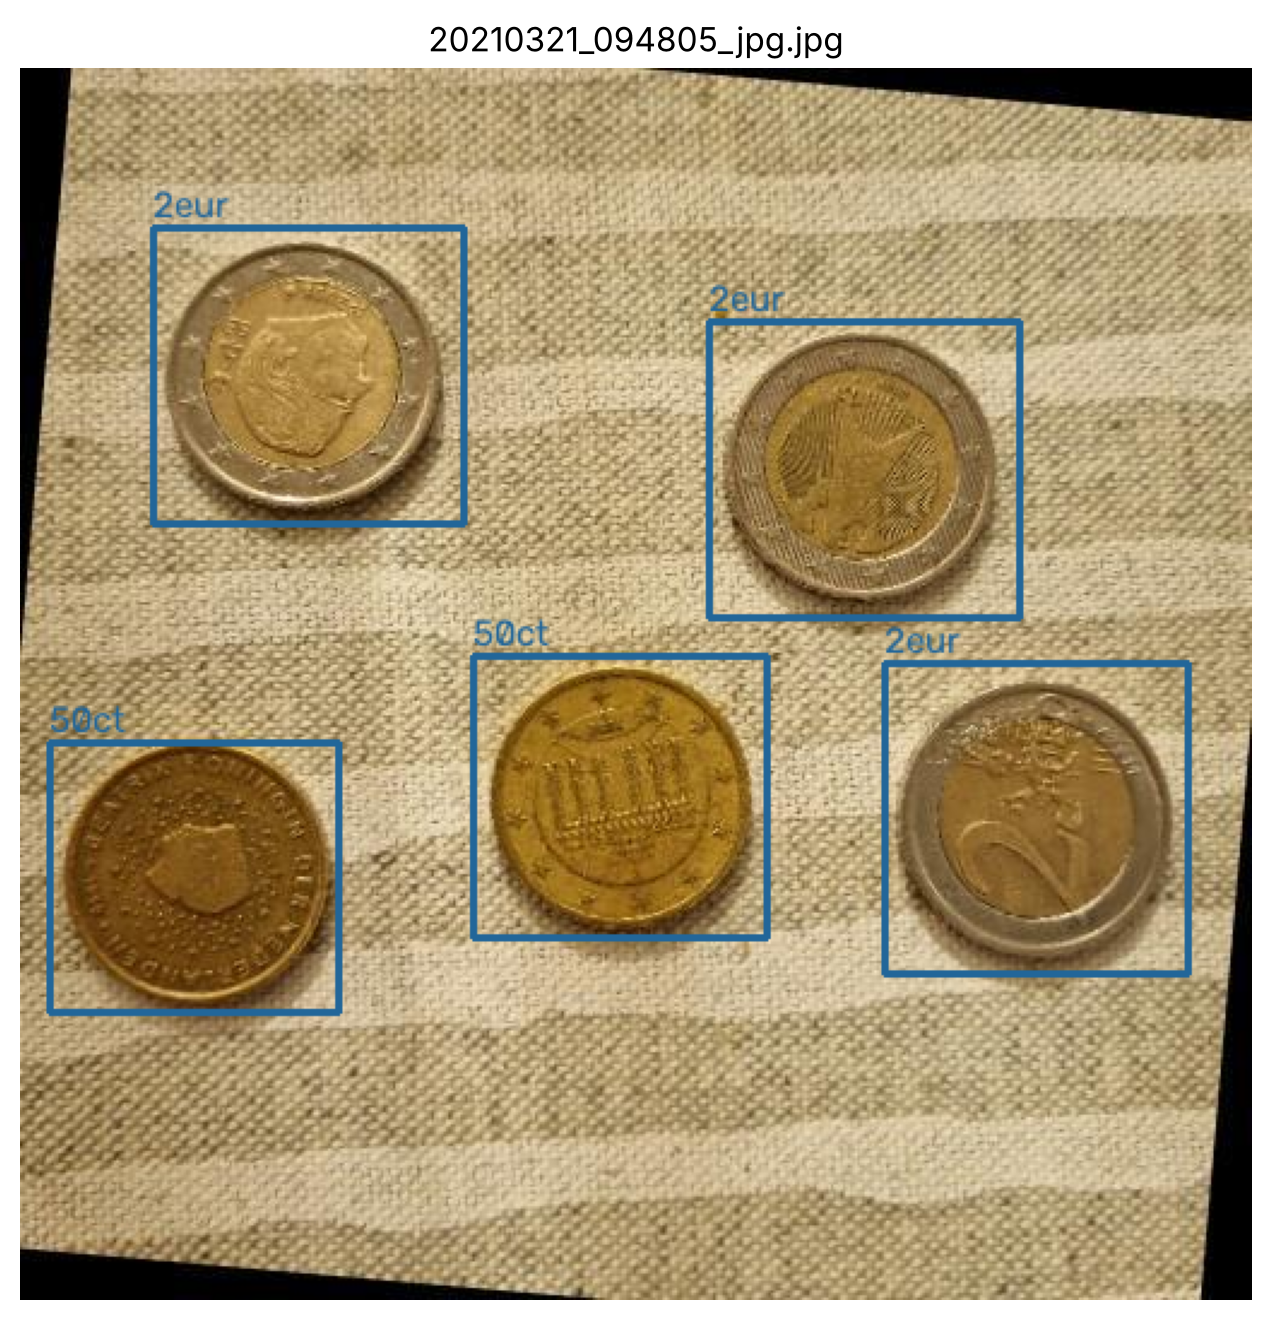

In [7]:
def draw_labels(dataset, split, name):
    image = cv2.imread(str(Path(dataset) / "images" / split / name))
    H, W = image.shape[:2]
    for _, z in df[df.image == name].iterrows():
        x1, y1 = int((z.xc - z.w / 2) * W), int((z.yc - z.h / 2) * H)
        x2, y2 = int((z.xc + z.w / 2) * W), int((z.yc + z.h / 2) * H)
        cv2.rectangle(image, (x1, y1), (x2, y2), (153, 102, 34), 2)
        cv2.putText(image, CLASSES[z.coin_class], (x1, y1 - 4), cv2.FONT_HERSHEY_SIMPLEX,
                    0.5, (153, 102, 34), 1, cv2.LINE_AA)
    return image


for name in df.image.unique()[:2]:
    show_image(draw_labels(target, "train", name), name)

## 4. Eigene Fotos ergänzen

Der Roboflow-Datensatz stammt aus einer anderen Umgebung: andere Kamera, anderer Untergrund, andere Höhe. Auf eigenen Fotos erkennt ein damit trainiertes Modell die Münzen deshalb schlecht. Abhilfe schaffen **Fotos aus der Einsatzumgebung**.

Die Fotos in `Datensätze/muenzen_eigen` wurden mit dem Handy aufgenommen, mit einem trainierten Modell **vorannotiert** (`Vorannotieren.py`) und anschließend in einem Annotationswerkzeug von Hand korrigiert.

**Aufteilen nach Szenen statt zufällig:** Kurz nacheinander aufgenommene Fotos zeigen meist dieselbe Münzanordnung. Landen sie teils im Training und teils im Test, ist das ein **Datenleck**. Wir fassen deshalb Fotos mit höchstens 30 Sekunden Abstand zu einer Szene zusammen und teilen ganze Szenen auf. Die beiden Demofotos der Vorlesung (`yolo_muenzen.jpg` und eine ältere Fassung) kommen samt ihrer Szene fest in den Test.

In [8]:
from datetime import datetime

SPLIT_PATTERN = ["train", "train", "val", "train", "train", "test"]
MAX_GAP = 30                               # Sekunden zwischen zwei Fotos derselben Szene
FORCE_TEST = {"PXL_20261118_181449503",     # = yolo_muenzen.jpg
              "PXL_20261117_110649849"}     # ältere Fassung des Demofotos


def group_by_time(images):
    """Fasst kurz nacheinander aufgenommene Fotos zu Szenen zusammen."""
    groups, last = [], None
    for image in sorted(images, key=lambda p: p.name):
        stamp = datetime.strptime(re.search(r"\d{8}_\d{6}", image.name).group(), "%Y%m%d_%H%M%S")
        if last is None or (stamp - last).total_seconds() > MAX_GAP:
            groups.append([])
        groups[-1].append(image)
        last = stamp
    return groups


def merge_own_photos(base_dataset, own_dir, target):
    base_dataset, own_dir, target = Path(base_dataset), Path(own_dir), Path(target)
    shutil.copytree(base_dataset, target, dirs_exist_ok=True)
    counts = {"train": 0, "val": 0, "test": 0}
    groups = group_by_time((own_dir / "images").glob("*.jpg"))
    for i, group in enumerate(groups):
        names = {p.stem for p in group}
        split = "test" if names & FORCE_TEST else SPLIT_PATTERN[i % len(SPLIT_PATTERN)]
        for image in group:
            shutil.copy(image, target / "images" / split / f"eigen_{image.name}")
            shutil.copy(own_dir / "labels" / f"{image.stem}.txt",
                        target / "labels" / split / f"eigen_{image.stem}.txt")
            counts[split] += 1
    write_data_yaml(target,
        "# muenzen_klein (Roboflow, Public Domain) und eigene Fotos (Präfix eigen_)\n")
    return len(groups), counts

In [9]:
own_dir = Path(base_path) / "Datensätze" / "muenzen_eigen"
combined = Path(base_path) / "Datensätze" / "muenzen_gesamt"
if not (combined / "data.yaml").exists():
    num_scenes, counts = merge_own_photos(target, own_dir, combined)
    print(num_scenes, "Szenen, eigene Fotos je Split:", counts)

for split in ["train", "val", "test"]:
    images = list((combined / "images" / split).glob("*.jpg"))
    own = sum(p.name.startswith("eigen_") for p in images)
    print(f"{split}: {len(images)} Bilder, davon {own} eigene")

19 Szenen, eigene Fotos je Split: {'train': 78, 'val': 15, 'test': 16}
train: 590 Bilder, davon 78 eigene
val: 161 Bilder, davon 15 eigene
test: 106 Bilder, davon 16 eigene


In [10]:
df_all, _ = read_labels(combined, "train")
df_all["source"] = df_all.image.str.startswith("eigen_").map({True: "eigen", False: "Roboflow"})
df_all.groupby(["source", "coin_class"]).size().unstack(0).rename(index=dict(enumerate(CLASSES)))

source,Roboflow,eigen
coin_class,,
1ct,573,42
2ct,552,106
5ct,498,78
10ct,556,70
20ct,424,114
50ct,365,23
1eur,395,32
2eur,303,67
